## Quantifying Cell-Type-Specific Distribution Shift Between Pseudo-Spatial scRNA-seq and Spatial Transcriptomics Data

#### Load Data

In [1]:
import pandas as pd
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# load training set
# train_adata = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/trainsets/syndri_predictions/chromium_breast_train_with_admix_probs.h5ad')
# train_adata = ad.concat([train_adata,ad.read_h5ad('/work/magroup/skrieger/Syndri/data/trainsets/syndri_predictions/chromium_breast_val_with_admix_probs.h5ad')])
train_adata = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/trainsets/parameter_tests/xenium_moreneighbors_truncatecounts.h5ad')

In [56]:
list(train_adata.obs.columns)
train_adata.obs['sampled_sc_id'].drop_duplicates()

GSM9509174_breast_breast_B1_B1_3:aaaaelkb-1        B1_ATGCACCTCGAGAGAAACTTTAGG-1
GSM9509174_breast_breast_B1_B1_3:aaabdcfd-1        B1_GGCTCAAAGCTCGATCACTTTAGG-1
GSM9509174_breast_breast_B1_B1_3:aaacnbab-1        B3_GCACACCGTTTGGGCCAACGGGAA-1
GSM9509174_breast_breast_B1_B1_3:aaadcaff-1    B4_rep_CCTACTTTCATGGAACATGTTGAC-1
GSM9509174_breast_breast_B1_B1_3:aaadeelf-1        B4_CATAATCTCTAAGTAGATGTTGAC-1
                                                             ...                
GSM9509174_breast_breast_B1_B1_3:ogmpphgd-1        B4_GATTGCTGTTTGCATAATGTTGAC-1
GSM9509174_breast_breast_B1_B1_3:ohaiiakd-1        B1_AGTCATAAGGCTTAAAACTTTAGG-1
GSM9509174_breast_breast_B1_B1_3:ohefkhbd-1    B3_rep_ACGGTAAGTGCCCTTTAGTAGGCT-1
GSM9509174_breast_breast_B1_B1_3:oihinnoj-1    B4_rep_CGGTGCACACTAGCGGATGTTGAC-1
GSM9509174_breast_breast_B1_B1_3:oiikahbi-1        B3_CATTGACGTTTGTGACAACGGGAA-1
Name: sampled_sc_id, Length: 5418, dtype: category
Categories (5418, object): ['B1_AAACAAGCAGGAATAAACTTTAGG-1

In [2]:
# add admixture
train_adata.layers['raw+admixed'] = train_adata.X + train_adata.layers['admixed_counts']

In [3]:
(train_adata.X>0).sum(axis=1).mean(),((train_adata.X + train_adata.layers['admixed_counts']) > 0) .sum(axis=1).mean()

(22.72115037614857, 29.14999676132841)

In [4]:
import os
spatial_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/'
files = sorted([f for f in os.listdir(spatial_dir) if f.endswith('1pct.h5ad') and f.startswith('GSM950')])
adata_list = []
for f in files:
    test_adata = ad.read_h5ad(os.path.join(spatial_dir,f))
    test_adata = test_adata[test_adata.obs.groupby('harmony_cell_type').sample(frac=0.05).index]
    adata_list.append(test_adata)
test_adata = ad.concat(adata_list)
del adata_list
test_adata.obs['cell_type'] = test_adata.obs['harmony_cell_type']

/tmp/ipykernel_3703357/3125037451.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  test_adata = test_adata[test_adata.obs.groupby('harmony_cell_type').sample(frac=0.05).index]
/tmp/ipykernel_3703357/3125037451.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  test_adata = test_adata[test_adata.obs.groupby('harmony_cell_type').sample(frac=0.05).index]
/tmp/ipykernel_3703357/3125037451.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and sile

In [5]:
(train_adata.layers['raw+admixed']>0).sum(axis=1).mean(), (test_adata.X>0).sum(axis=1).mean()

(29.14999676132841, 45.98452696728559)

In [6]:
test_adata.X.max(axis=1).max(),train_adata.layers['raw+admixed'].max(axis=1).max(),


(189, 453.0)

In [7]:
# load single ST tissue
gene_adata = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/GSM9509174_breast_breast_B1_B1_3_rctd_annotated_dropout_1pct.h5ad')

# ensembl to gene name mapping
gene_dict = dict(zip(gene_adata.var.index,gene_adata.var.feature_name))
del gene_adata

/tmp/ipykernel_3703357/1234736521.py:104: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


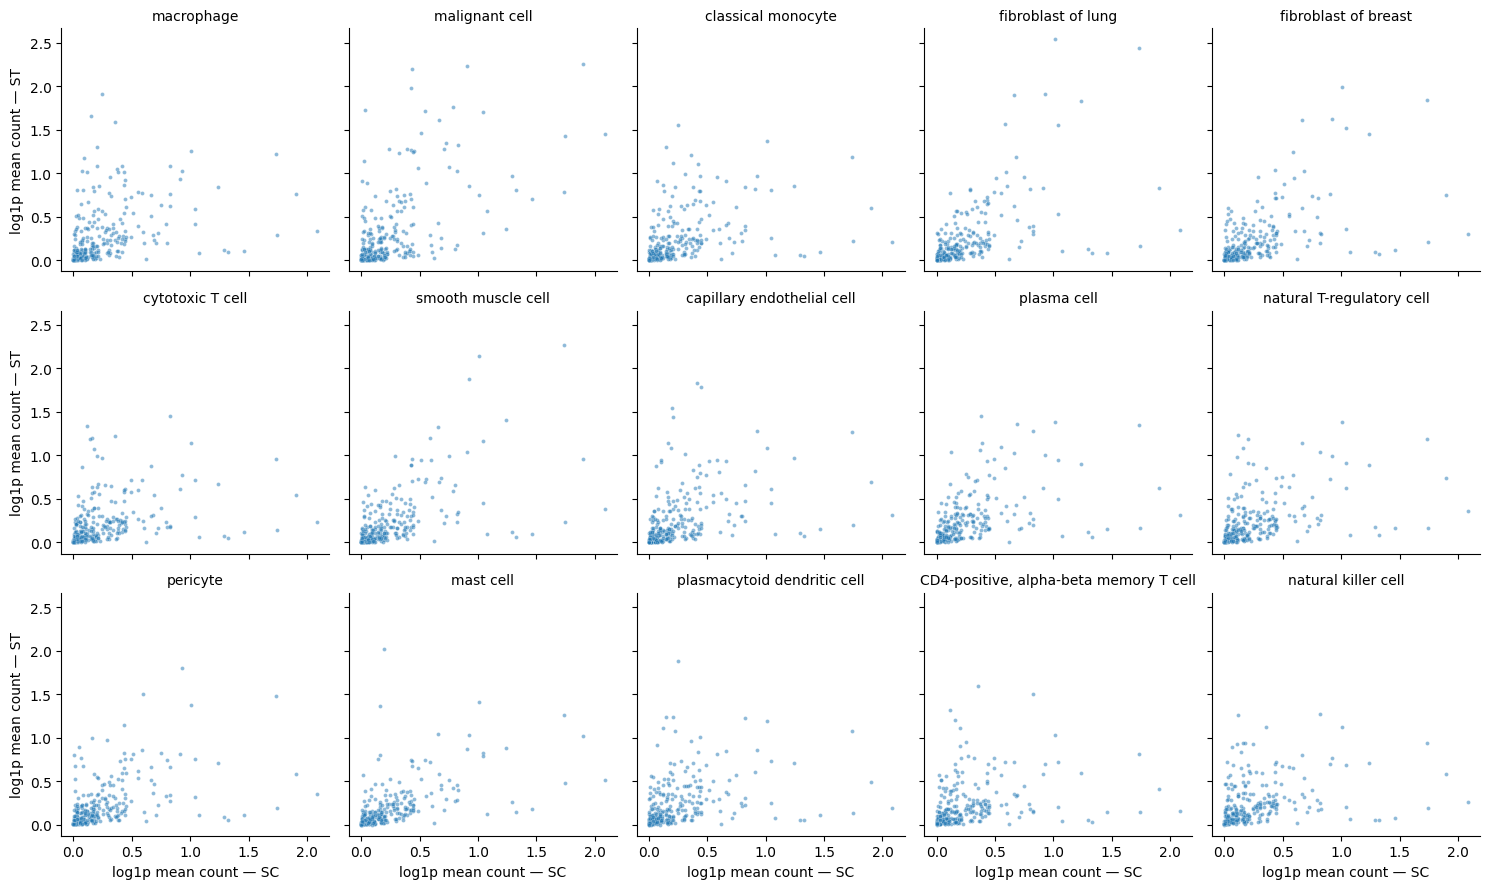

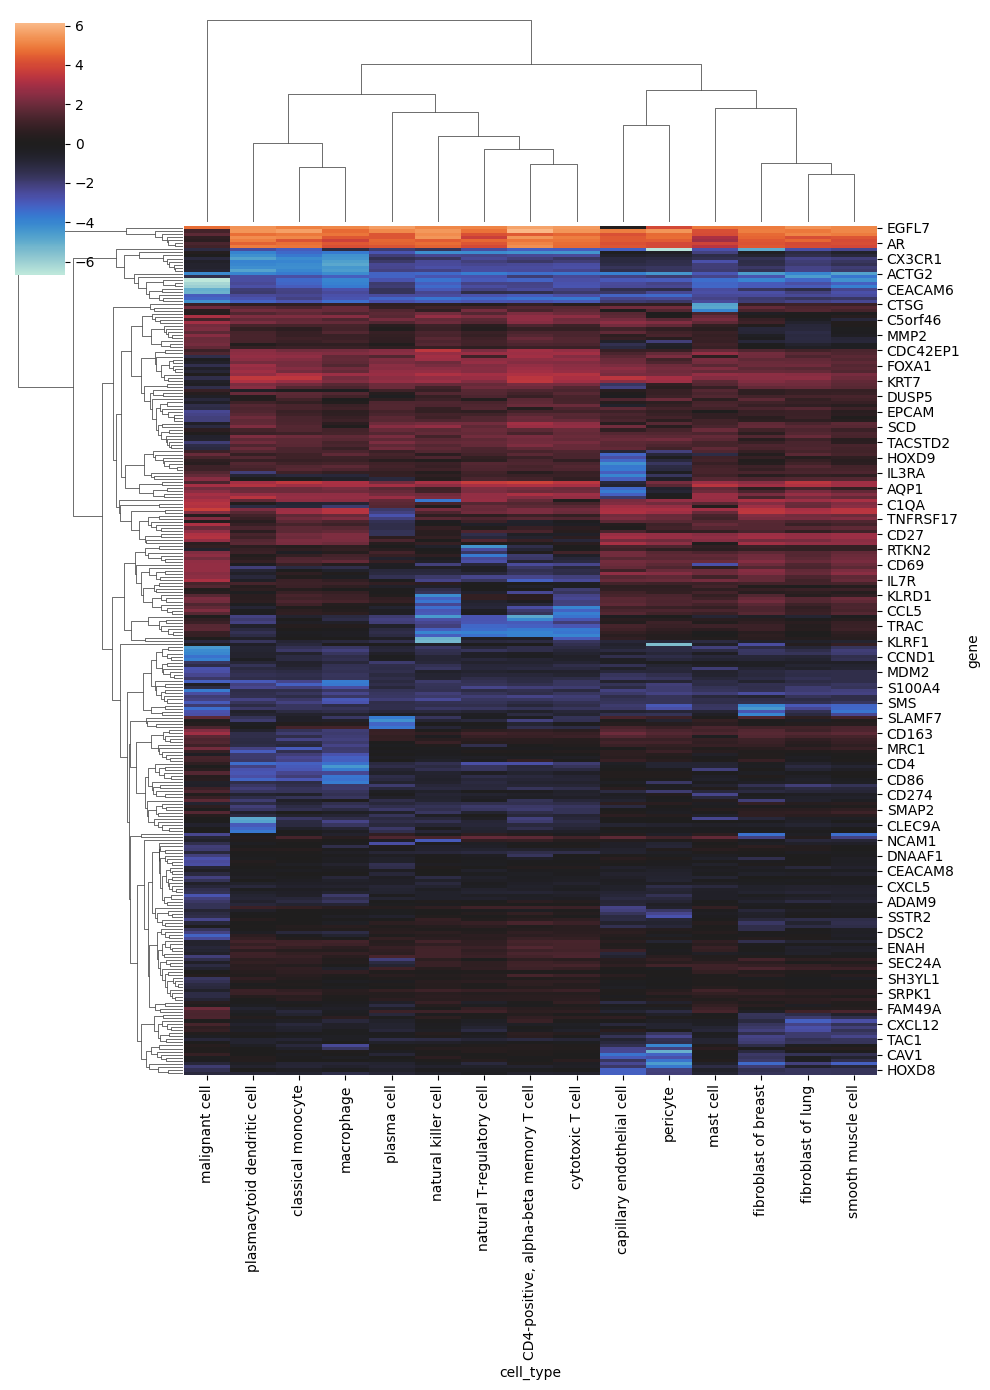

In [8]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import spearmanr, pearsonr
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import spearmanr

def summarize_genes_by_cell_type(
    adata,
    cell_type_col,
    layer=None,
    genes=None,
):
    if genes is None:
        genes = adata.var_names

    # make sure ordering is explicit
    genes = pd.Index(genes)
    gene_idx = adata.var_names.get_indexer(genes)

    rows = []

    for cell_type in adata.obs[cell_type_col].dropna().unique():

        mask = adata.obs[cell_type_col].eq(cell_type).values
        if layer is not None:
            X = adata.layers[layer][:, gene_idx]
        else:
            X = adata.X[mask][:, gene_idx]

        if sp.issparse(X):
            X = X.tocsr()

            mean_all = np.asarray(X.mean(axis=0)).ravel()

            n_detected = np.asarray(
                (X > 0).sum(axis=0)
            ).ravel()

            sums = np.asarray(
                X.sum(axis=0)
            ).ravel()

        else:
            mean_all = X.mean(axis=0)
            n_detected = (X > 0).sum(axis=0)
            sums = X.sum(axis=0)

        mean_detected = np.divide(
            sums,
            n_detected,
            out=np.zeros(len(genes), dtype=float),
            where=n_detected > 0,
        )

        detection = n_detected / mask.sum()

        rows.append(
            pd.DataFrame({
                "cell_type": cell_type,
                "gene": genes,
                "mean_all": mean_all,
                "mean_detected": mean_detected,
                "detection": detection,
                "n_cells": mask.sum(),
            })
        )

    return pd.concat(rows, ignore_index=True)

shared_genes = train_adata.var_names.intersection(
    test_adata.var_names
)

sc_summary = summarize_genes_by_cell_type(
    train_adata,
    layer='raw+admixed',
    cell_type_col="cell_type",   # change this
    genes=shared_genes,
)

st_summary = summarize_genes_by_cell_type(
    test_adata,
    cell_type_col="cell_type",   # e.g. harmony_cell_type
    genes=shared_genes,
)

gene_ct_df = sc_summary.merge(
    st_summary,
    on=["cell_type", "gene"],
    suffixes=("_sc", "_st"),
)

gene_ct_df['gene'] = gene_ct_df['gene'].map(gene_dict)

correlations = (
    gene_ct_df
    .groupby("cell_type")
    .apply(
        lambda x: pd.Series({
            "spearman_mean_all": spearmanr(
                x["mean_all_sc"],
                x["mean_all_st"]
            ).statistic,

            "spearman_mean_detected": spearmanr(
                x["mean_detected_sc"],
                x["mean_detected_st"]
            ).statistic,

            "n_genes": len(x),
            "n_cells_sc": x["n_cells_sc"].iloc[0],
            "n_cells_st": x["n_cells_st"].iloc[0],
        })
    )
    .reset_index()
)

correlations.sort_values("spearman_mean_all", ascending=False)

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = gene_ct_df.copy()

plot_df["log_mean_sc"] = np.log1p(
    plot_df["mean_all_sc"]
)

plot_df["log_mean_st"] = np.log1p(
    plot_df["mean_all_st"]
)

g = sns.FacetGrid(
    plot_df,
    col="cell_type",
    col_wrap=5,
    height=3,
    sharex=True,
    sharey=True,
)

g.map_dataframe(
    sns.scatterplot,
    x="log_mean_sc",
    y="log_mean_st",
    s=8,
    alpha=0.5,
)

g.set_axis_labels(
    "log1p mean count — SC",
    "log1p mean count — ST",
)

# for ax in g.axes.flat:
#     xlim = ax.get_xlim()
#     ylim = ax.get_ylim()

#     lo = min(xlim[0], ylim[0])
#     hi = max(xlim[1], ylim[1])

#     ax.plot(
#         [lo, hi],
#         [lo, hi],
#         "--",
#         linewidth=0.8,
#     )
g.set_titles("{col_name}")

plt.tight_layout()


gene_ct_df["log2_sc_st_ratio"] = np.log2(
    (gene_ct_df["mean_all_sc"] + 0.01) /
    (gene_ct_df["mean_all_st"] + 0.01)
)

ratio_matrix = gene_ct_df.pivot(
    index="gene",
    columns="cell_type",
    values="log2_sc_st_ratio",
)

sns.clustermap(
    ratio_matrix,
    center=0,
    figsize=(10, 14),
)


In [9]:
from scipy.stats import spearmanr

corr_df = (
    gene_ct_df
    .groupby("cell_type")
    .apply(
        lambda x: spearmanr(
            x["mean_all_sc"],
            x["mean_all_st"]
        ).statistic
    )
    .rename("spearman_r")
    .reset_index()
)

corr_df.sort_values("spearman_r")




/tmp/ipykernel_3703357/3442363834.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,cell_type,spearman_r
13,plasmacytoid dendritic cell,0.576766
10,natural killer cell,0.579691
0,"CD4-positive, alpha-beta memory T cell",0.587482
3,cytotoxic T cell,0.599929
6,macrophage,0.609177
7,malignant cell,0.615509
11,pericyte,0.638581
2,classical monocyte,0.647181
9,natural T-regulatory cell,0.652062
4,fibroblast of breast,0.653341


In [10]:
import numpy as np
import pandas as pd
import scipy.sparse as sp


def get_matrix(adata, obs_mask, genes, layer=None):
    """
    Extract an AnnData matrix for selected cells and genes.

    layer=None
        -> use adata.X

    layer="admixed_counts"
        -> use adata.layers["admixed_counts"]
    """
    adata_subset = adata[obs_mask, genes]

    if layer is None:
        return adata_subset.X

    if layer not in adata.layers:
        raise ValueError(
            f"Layer '{layer}' not found. "
            f"Available layers: {list(adata.layers.keys())}"
        )

    return adata_subset.layers[layer]


def detection_frequency(X):
    """
    Fraction of cells with expression > 0 for each gene.
    Works for dense or sparse matrices.
    """
    if sp.issparse(X):
        return np.asarray(
            (X > 0).mean(axis=0)
        ).ravel()

    X = np.asarray(X)
    return (X > 0).mean(axis=0)


def compare_detection_by_cell_type(
    train_adata,
    test_adata,
    cell_type_col="cell_type",
    train_layer=None,
    test_layer=None,
    min_cells=1,
):
    """
    Compare per-gene detection frequencies between train and test
    separately for every cell type represented in both datasets.

    Parameters
    ----------
    train_layer : str or None
        None uses train_adata.X.
        For example, "admixed_counts" uses
        train_adata.layers["admixed_counts"].

    test_layer : str or None
        Same behavior for test_adata. Defaults to .X.

    min_cells : int
        Require at least this many cells of a cell type in both
        train and test.
    """

    # Genes available in both datasets
    common_genes = train_adata.var_names.intersection(
        test_adata.var_names
    )

    train_labels = (
        train_adata.obs[cell_type_col]
        .astype("string")
    )

    test_labels = (
        test_adata.obs[cell_type_col]
        .astype("string")
    )

    # Cell types represented in both train and test
    common_cell_types = sorted(
        set(train_labels.dropna())
        & set(test_labels.dropna())
    )

    results = []

    for cell_type in common_cell_types:

        train_mask = train_labels.eq(cell_type).fillna(False).to_numpy()
        test_mask = test_labels.eq(cell_type).fillna(False).to_numpy()

        n_train = train_mask.sum()
        n_test = test_mask.sum()

        if n_train < min_cells or n_test < min_cells:
            continue

        train_X = get_matrix(
            train_adata,
            train_mask,
            common_genes,
            layer=train_layer,
        )

        test_X = get_matrix(
            test_adata,
            test_mask,
            common_genes,
            layer=test_layer,
        )

        train_detection = detection_frequency(train_X)
        test_detection = detection_frequency(test_X)

        cell_type_df = pd.DataFrame({
            "cell_type": cell_type,
            "gene": common_genes,
            "n_train": n_train,
            "n_test": n_test,
            "train_detection": train_detection,
            "test_detection": test_detection,
        })
        cell_type_df['gene_name'] = cell_type_df['gene'].map(gene_dict)

        cell_type_df["detection_delta"] = (
            cell_type_df["test_detection"]
            - cell_type_df["train_detection"]
        )

        cell_type_df["abs_detection_delta"] = (
            cell_type_df["detection_delta"].abs()
        )

        results.append(cell_type_df)

    return pd.concat(
        results,
        ignore_index=True,
    )

raw_detection_df = compare_detection_by_cell_type(
    train_adata,
    test_adata,
    cell_type_col="cell_type",
    train_layer=None,              # train .X
    test_layer=None,               # test .X
)

admixed_detection_df = compare_detection_by_cell_type(
    train_adata,
    test_adata,
    cell_type_col="cell_type",
    train_layer="raw+admixed",  # train admixed counts
    test_layer=None,               # test .X
)

In [11]:
admixed_detection_df

,cell_type,gene,n_train,n_test,train_detection,test_detection,gene_name,detection_delta,abs_detection_delta
0,"CD4-positive, alpha-beta memory T cell",ENSG00000121270,1946,1180,0.194758,0.036441,ABCC11,-0.158318,0.158318
1,"CD4-positive, alpha-beta memory T cell",ENSG00000107796,1946,1180,0.016958,0.434746,ACTA2,0.417788,0.417788
2,"CD4-positive, alpha-beta memory T cell",ENSG00000163017,1946,1180,0.000000,0.199153,ACTG2,0.199153,0.199153
3,"CD4-positive, alpha-beta memory T cell",ENSG00000168615,1946,1180,0.019013,0.188983,ADAM9,0.169970,0.169970
4,"CD4-positive, alpha-beta memory T cell",ENSG00000123146,1946,1180,0.221994,0.409322,ADGRE5,0.187328,0.187328
...,...,...,...,...,...,...,...,...,...
4150,smooth muscle cell,ENSG00000110799,7891,6463,0.012546,0.039301,VWF,0.026755,0.026755
4151,smooth muscle cell,ENSG00000140105,7891,6463,0.032822,0.216927,WARS,0.184105,0.184105
4152,smooth muscle cell,ENSG00000148516,7891,6463,0.418325,0.388519,ZEB1,-0.029805,0.029805
4153,smooth muscle cell,ENSG00000169554,7891,6463,0.294893,0.518335,ZEB2,0.223442,0.223442


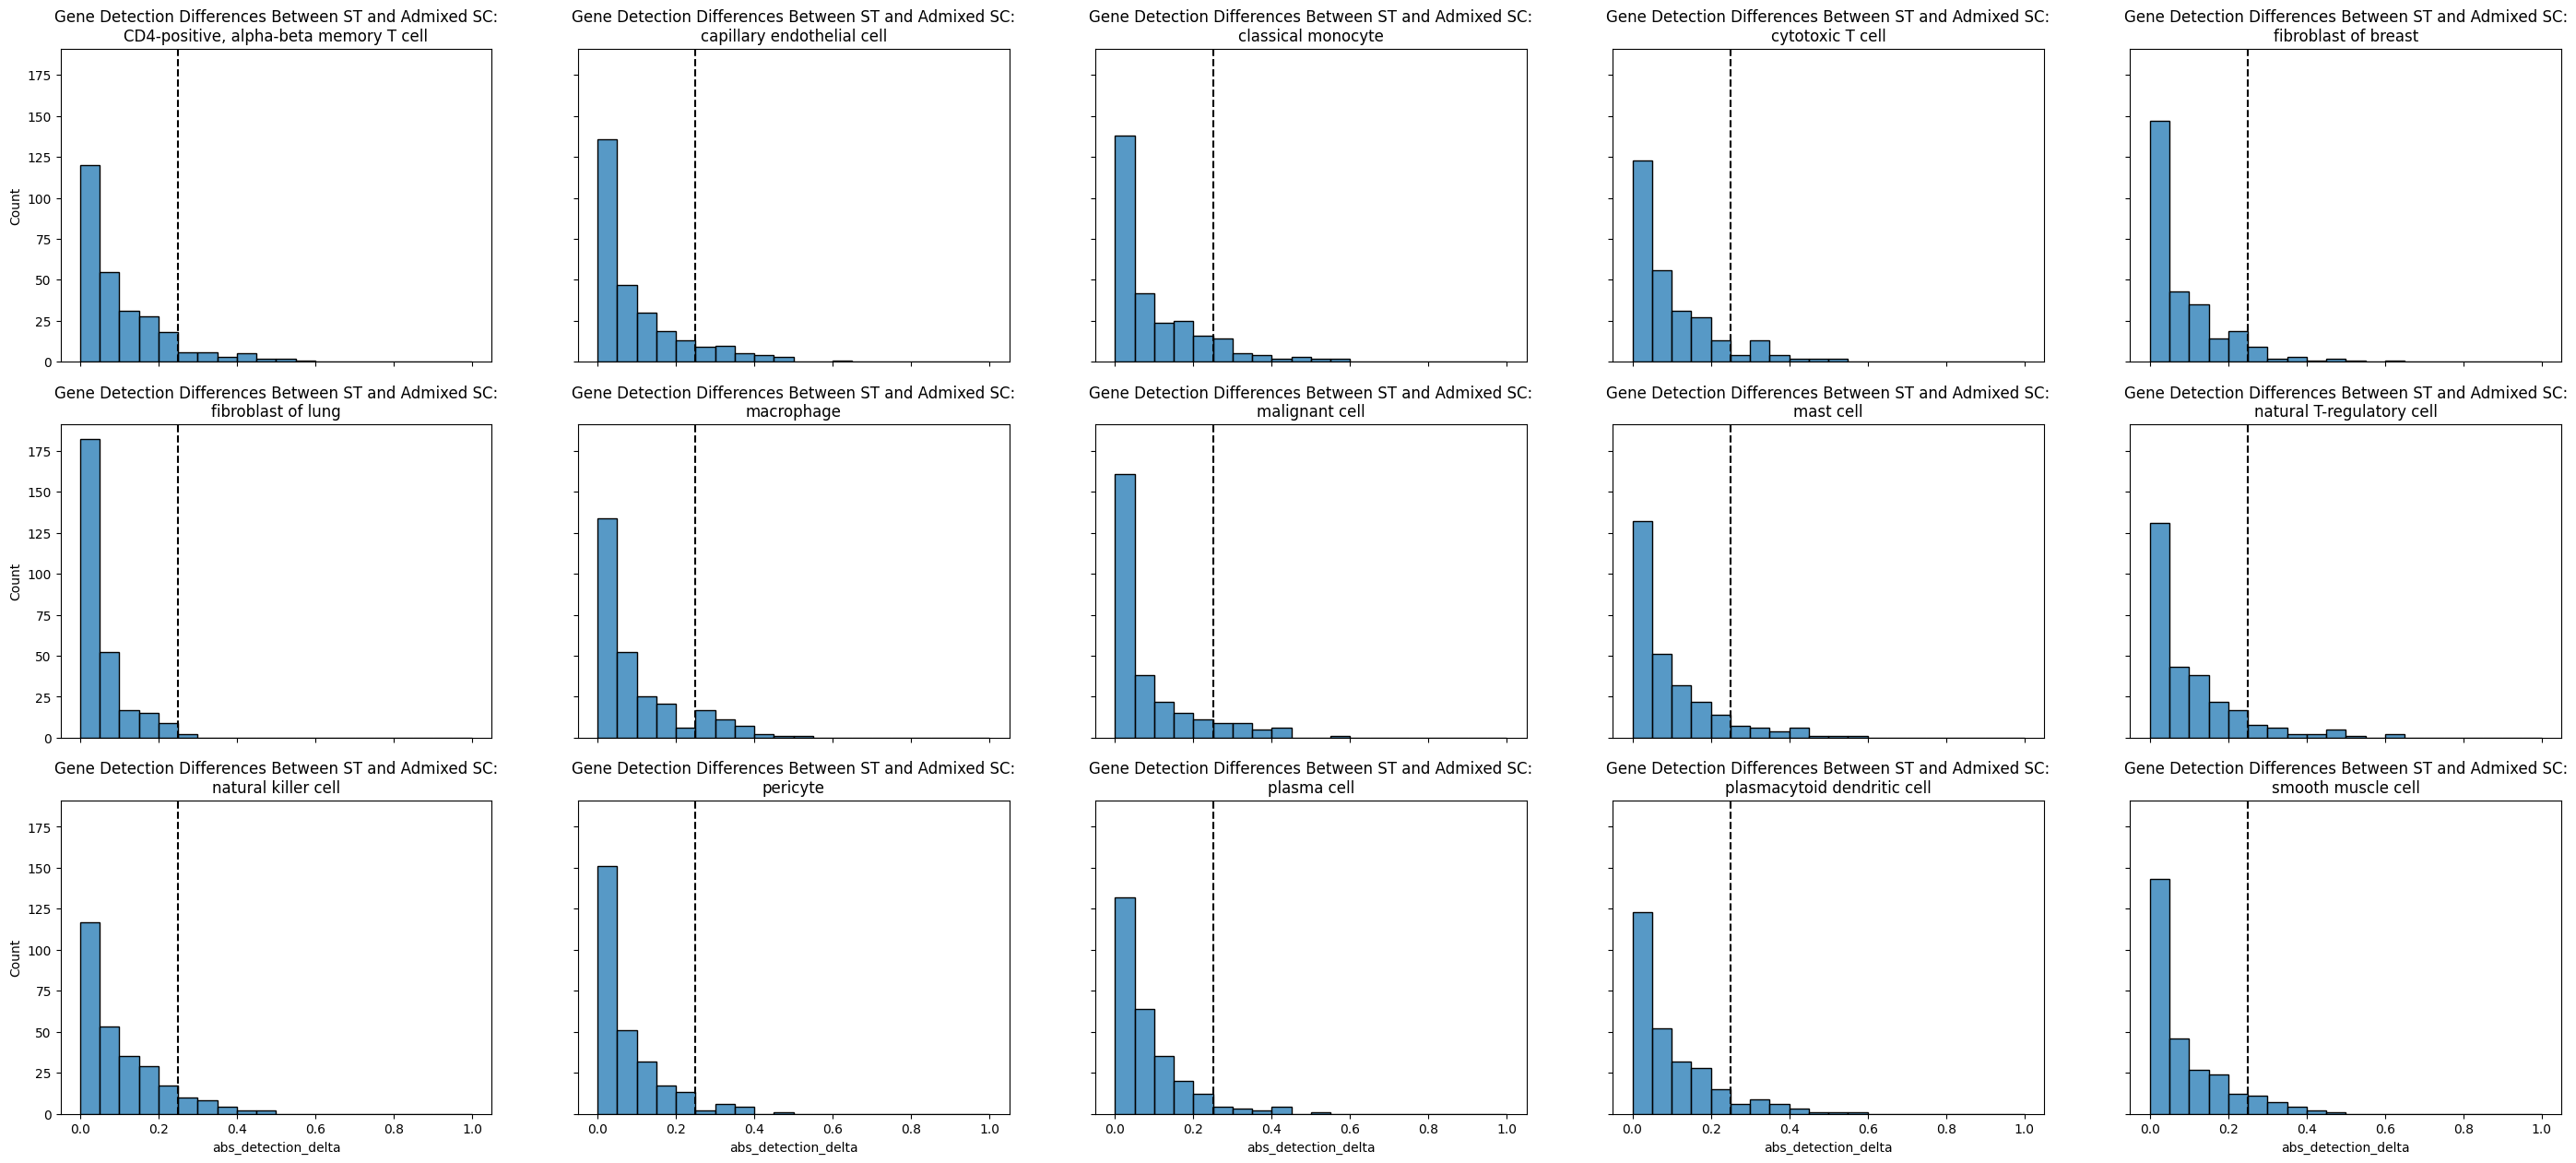

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
admixed_detection_df#[admixed_detection_df['cell_type'].str.contains('fibroblast')].sort_values(by=['cell_type','abs_detection_delta'],ascending=[True,False])
NROWS=3
NCOLS=5
cell_types = sorted(admixed_detection_df['cell_type'].unique().tolist())
fig,axes= plt.subplots(nrows=NROWS,ncols=NCOLS,figsize=(7*NCOLS,5*NROWS),sharex=True,sharey=True)
for i,ct in enumerate(cell_types):
    ax = axes.flat[i]
    sns.histplot(admixed_detection_df[(admixed_detection_df['cell_type']==ct)],x='abs_detection_delta',ax=ax,bins=np.arange(0,1.01,0.05))
    ax.set_title(f'Gene Detection Differences Between ST and Admixed SC:\n{ct}')
    ax.axvline(x=0.25,c='black',linestyle='--')

In [13]:
detection_summary = (
    admixed_detection_df
    .groupby("cell_type")
    .agg(
        median_abs_delta=("abs_detection_delta", "median"),
        mean_abs_delta=("abs_detection_delta", "mean"),
        q90_abs_delta=("abs_detection_delta", lambda x: x.quantile(0.90)),
        q95_abs_delta=("abs_detection_delta", lambda x: x.quantile(0.95)),
        max_abs_delta=("abs_detection_delta", "max"),
        frac_gt_0_10=("abs_detection_delta", lambda x: (x > 0.10).mean()),
        frac_gt_0_25=("abs_detection_delta", lambda x: (x > 0.25).mean()),
        frac_gt_0_50=("abs_detection_delta", lambda x: (x > 0.50).mean()),
    )
)

detection_summary

admixed_detection_df["direction"] = np.where(
    admixed_detection_df["detection_delta"] > 0,
    "Higher in ST",
    "Higher in training SC",
)

large_shifts = admixed_detection_df[
    admixed_detection_df["abs_detection_delta"] > 0.25
]

pd.crosstab(
    large_shifts["cell_type"],
    large_shifts["direction"],
)

direction,Higher in ST,Higher in training SC
cell_type,,
"CD4-positive, alpha-beta memory T cell",25,0
capillary endothelial cell,31,1
classical monocyte,32,0
cytotoxic T cell,27,0
fibroblast of breast,19,0
fibroblast of lung,2,0
macrophage,36,3
malignant cell,25,5
mast cell,24,2


In [14]:
comparison_df = raw_detection_df.merge(
    admixed_detection_df,
    on=["cell_type", "gene"],
    suffixes=("_raw", "_admixed"),
)

comparison_df["change_in_abs_shift"] = (
    comparison_df["abs_detection_delta_admixed"]
    - comparison_df["abs_detection_delta_raw"]
)

cell_type_comparison = (
    comparison_df
    .groupby("cell_type")
    .agg(
        raw_mean_abs_shift=(
            "abs_detection_delta_raw",
            "mean",
        ),
        admixed_mean_abs_shift=(
            "abs_detection_delta_admixed",
            "mean",
        ),
        mean_change=(
            "change_in_abs_shift",
            "mean",
        ),
        raw_median_abs_shift=(
            "abs_detection_delta_raw",
            "median",
        ),
        admixed_median_abs_shift=(
            "abs_detection_delta_admixed",
            "median",
        ),
    )
)

cell_type_comparison["relative_change"] = (
    cell_type_comparison["admixed_mean_abs_shift"]
    / cell_type_comparison["raw_mean_abs_shift"]
)

cell_type_comparison.sort_values("mean_change")


cell_type_comparison = (
    comparison_df
    .groupby("cell_type")
    .agg(
        raw_mean_abs_shift=(
            "abs_detection_delta_raw",
            "mean",
        ),
        admixed_mean_abs_shift=(
            "abs_detection_delta_admixed",
            "mean",
        ),
        mean_change=(
            "change_in_abs_shift",
            "mean",
        ),
        raw_median_abs_shift=(
            "abs_detection_delta_raw",
            "median",
        ),
        admixed_median_abs_shift=(
            "abs_detection_delta_admixed",
            "median",
        ),
    )
)

cell_type_comparison["relative_change"] = (
    cell_type_comparison["admixed_mean_abs_shift"]
    / cell_type_comparison["raw_mean_abs_shift"]
)

cell_type_comparison.sort_values("mean_change")

,raw_mean_abs_shift,admixed_mean_abs_shift,mean_change,raw_median_abs_shift,admixed_median_abs_shift,relative_change
cell_type,,,,,,
malignant cell,0.100108,0.085981,-0.014127,0.047514,0.038418,0.858885
plasma cell,0.093755,0.080099,-0.013656,0.061590,0.052044,0.854346
macrophage,0.110982,0.097381,-0.013601,0.063639,0.053597,0.877450
natural killer cell,0.113874,0.101674,-0.012200,0.080991,0.070671,0.892863
plasmacytoid dendritic cell,0.113472,0.101651,-0.011821,0.079676,0.062614,0.895827
capillary endothelial cell,0.109364,0.097828,-0.011536,0.063312,0.050688,0.894515
classical monocyte,0.110374,0.099876,-0.010498,0.063569,0.051679,0.904891
fibroblast of lung,0.061247,0.051062,-0.010185,0.032783,0.026869,0.833711
smooth muscle cell,0.096470,0.086486,-0.009983,0.054378,0.045207,0.896515


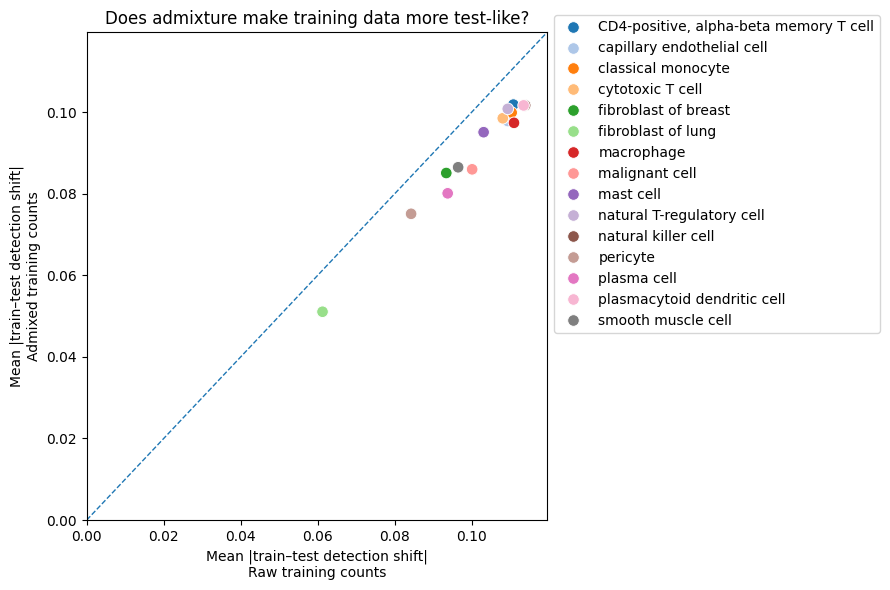

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=cell_type_comparison.reset_index(),
    x="raw_mean_abs_shift",
    y="admixed_mean_abs_shift",
    s=70,
    ax=ax,
    hue='cell_type',
    palette='tab20',
)

lims = [
    0,
    max(
        cell_type_comparison["raw_mean_abs_shift"].max(),
        cell_type_comparison["admixed_mean_abs_shift"].max(),
    ) * 1.05,
]

ax.plot(
    lims,
    lims,
    linestyle="--",
    linewidth=1,
)

ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel(
    "Mean |train–test detection shift|\nRaw training counts"
)

ax.set_ylabel(
    "Mean |train–test detection shift|\nAdmixed training counts"
)

ax.set_title(
    "Does admixture make training data more test-like?"
)
ax.legend(bbox_to_anchor=(1,1.05))
fig.tight_layout()

In [16]:
import numpy as np
import pandas as pd
import scipy.sparse as sp

from scipy.stats import wasserstein_distance


def get_gene_values(
    adata,
    cell_mask,
    gene,
    layer=None,
):
    """
    Get expression values for one gene across selected cells.
    """

    adata_subset = adata[cell_mask, [gene]]

    if layer is None:
        X = adata_subset.X
    else:
        X = adata_subset.layers[layer]

    if sp.issparse(X):
        values = X.toarray().ravel()
    else:
        values = np.asarray(X).ravel()

    return values


def characterize_detected_expression(
    train_adata,
    test_adata,
    detection_df,
    cell_type_col="cell_type",
    train_layer="admixed_counts",
    test_layer=None,
    detection_threshold=0.25,
):
    """
    Characterize expression conditional on detection for genes
    with large train-test detection differences.
    """

    # Only genes with large detection-frequency shifts
    shifted_genes = detection_df.loc[
        detection_df["abs_detection_delta"] > detection_threshold
    ].copy()

    train_labels = (
        train_adata.obs[cell_type_col]
        .astype("string")
    )

    test_labels = (
        test_adata.obs[cell_type_col]
        .astype("string")
    )

    rows = []

    for _, detection_row in shifted_genes.iterrows():

        cell_type = detection_row["cell_type"]
        gene = detection_row["gene"]

        train_mask = (
            train_labels.eq(cell_type)
            .fillna(False)
            .to_numpy()
        )

        test_mask = (
            test_labels.eq(cell_type)
            .fillna(False)
            .to_numpy()
        )

        train_values = get_gene_values(
            train_adata,
            train_mask,
            gene,
            layer=train_layer,
        )

        test_values = get_gene_values(
            test_adata,
            test_mask,
            gene,
            layer=test_layer,
        )

        # Conditional on detection
        train_nonzero = train_values[
            train_values > 0
        ]

        test_nonzero = test_values[
            test_values > 0
        ]

        if (
            len(train_nonzero) == 0
            or len(test_nonzero) == 0
        ):
            continue

        # log1p distributions for a more stable
        # comparison of count magnitudes
        train_log = np.log1p(train_nonzero)
        test_log = np.log1p(test_nonzero)

        rows.append({
            "cell_type": cell_type,
            "gene": gene,

            # Existing detection information
            "train_detection":
                detection_row["train_detection"],
            "test_detection":
                detection_row["test_detection"],
            "detection_delta":
                detection_row["detection_delta"],
            "abs_detection_delta":
                detection_row["abs_detection_delta"],

            # Number of detected cells
            "n_detected_train": len(train_nonzero),
            "n_detected_test": len(test_nonzero),

            # Raw count summaries
            "train_mean_nonzero":
                np.mean(train_nonzero),
            "test_mean_nonzero":
                np.mean(test_nonzero),

            "train_median_nonzero":
                np.median(train_nonzero),
            "test_median_nonzero":
                np.median(test_nonzero),

            "train_q25_nonzero":
                np.quantile(train_nonzero, 0.25),
            "train_q75_nonzero":
                np.quantile(train_nonzero, 0.75),

            "test_q25_nonzero":
                np.quantile(test_nonzero, 0.25),
            "test_q75_nonzero":
                np.quantile(test_nonzero, 0.75),

            # Conditional expression difference
            "median_log1p_train":
                np.median(train_log),
            "median_log1p_test":
                np.median(test_log),

            "median_log1p_delta":
                np.median(test_log)
                - np.median(train_log),

            # Full conditional-distribution difference
            "wasserstein_log1p":
                wasserstein_distance(
                    train_log,
                    test_log,
                ),
        })

    return pd.DataFrame(rows)

expression_shift_df = characterize_detected_expression(
    train_adata,
    test_adata,
    admixed_detection_df,
    cell_type_col="cell_type",
    train_layer="raw+admixed",
    test_layer=None,
    detection_threshold=0.25,
)

expression_shift_df.head()

,cell_type,gene,train_detection,test_detection,detection_delta,abs_detection_delta,n_detected_train,n_detected_test,train_mean_nonzero,test_mean_nonzero,train_median_nonzero,test_median_nonzero,train_q25_nonzero,train_q75_nonzero,test_q25_nonzero,test_q75_nonzero,median_log1p_train,median_log1p_test,median_log1p_delta,wasserstein_log1p
0,"CD4-positive, alpha-beta memory T cell",ENSG00000107796,0.016958,0.434746,0.417788,0.417788,33,513,5.757576,2.296296,4.0,1.0,2.0,6.0,1.0,3.0,1.609438,0.693147,-9.162908e-01,0.554250
1,"CD4-positive, alpha-beta memory T cell",ENSG00000204472,0.012333,0.302542,0.290209,0.290209,24,357,1.500000,1.565826,1.0,1.0,1.0,2.0,1.0,2.0,0.693147,0.693147,-1.904654e-09,0.032269
2,"CD4-positive, alpha-beta memory T cell",ENSG00000091986,0.026208,0.450847,0.424640,0.424640,51,532,4.686275,2.332707,1.0,2.0,1.0,3.0,1.0,3.0,0.693147,1.098612,4.054651e-01,0.244639
3,"CD4-positive, alpha-beta memory T cell",ENSG00000198821,0.077595,0.430508,0.352913,0.352913,151,508,1.615894,1.566929,2.0,1.0,1.0,2.0,1.0,2.0,1.098612,0.693147,-4.054651e-01,0.107471
4,"CD4-positive, alpha-beta memory T cell",ENSG00000198851,0.491778,0.764407,0.272629,0.272629,957,902,1.733542,3.073171,2.0,3.0,1.0,2.0,1.0,4.0,1.098612,1.386294,2.876821e-01,0.321184


In [28]:
cell_type_expression_summary = (
    expression_shift_df
    .groupby("cell_type")
    .agg(
        n_large_detection_shift_genes=(
            "gene",
            "size",
        ),
        median_expression_delta=(
            "median_log1p_delta",
            "median",
        ),
        median_abs_expression_delta=(
            "median_log1p_delta",
            lambda x: np.median(np.abs(x)),
        ),
        median_wasserstein=(
            "wasserstein_log1p",
            "median",
        ),
        fraction_higher_expression_in_ST=(
            "median_log1p_delta",
            lambda x: (x > 0).mean(),
        ),
    )
)

cell_type_expression_summary

,n_large_detection_shift_genes,median_expression_delta,median_abs_expression_delta,median_wasserstein,fraction_higher_expression_in_ST
cell_type,,,,,
"CD4-positive, alpha-beta memory T cell",24,-1.904654e-09,4.054651e-01,0.299595,0.291667
capillary endothelial cell,34,-1.904654e-09,2.876821e-01,0.181658,0.323529
classical monocyte,31,-1.904654e-09,4.054651e-01,0.150050,0.258065
cytotoxic T cell,28,-1.904654e-09,1.086937e-08,0.163352,0.107143
fibroblast of breast,24,-1.904654e-09,1.013663e-01,0.199952,0.375000
fibroblast of lung,5,-1.904654e-09,1.904654e-09,0.092918,0.200000
macrophage,40,-1.904654e-09,1.115718e-01,0.194371,0.325000
malignant cell,34,2.876821e-01,4.054651e-01,0.270740,0.529412
mast cell,28,-1.182170e-08,1.438410e-01,0.316284,0.142857


upper_right     28.020566
upper_left       0.257069
lower_left       3.856041
lower_right     67.866324
n              389.000000
dtype: float64

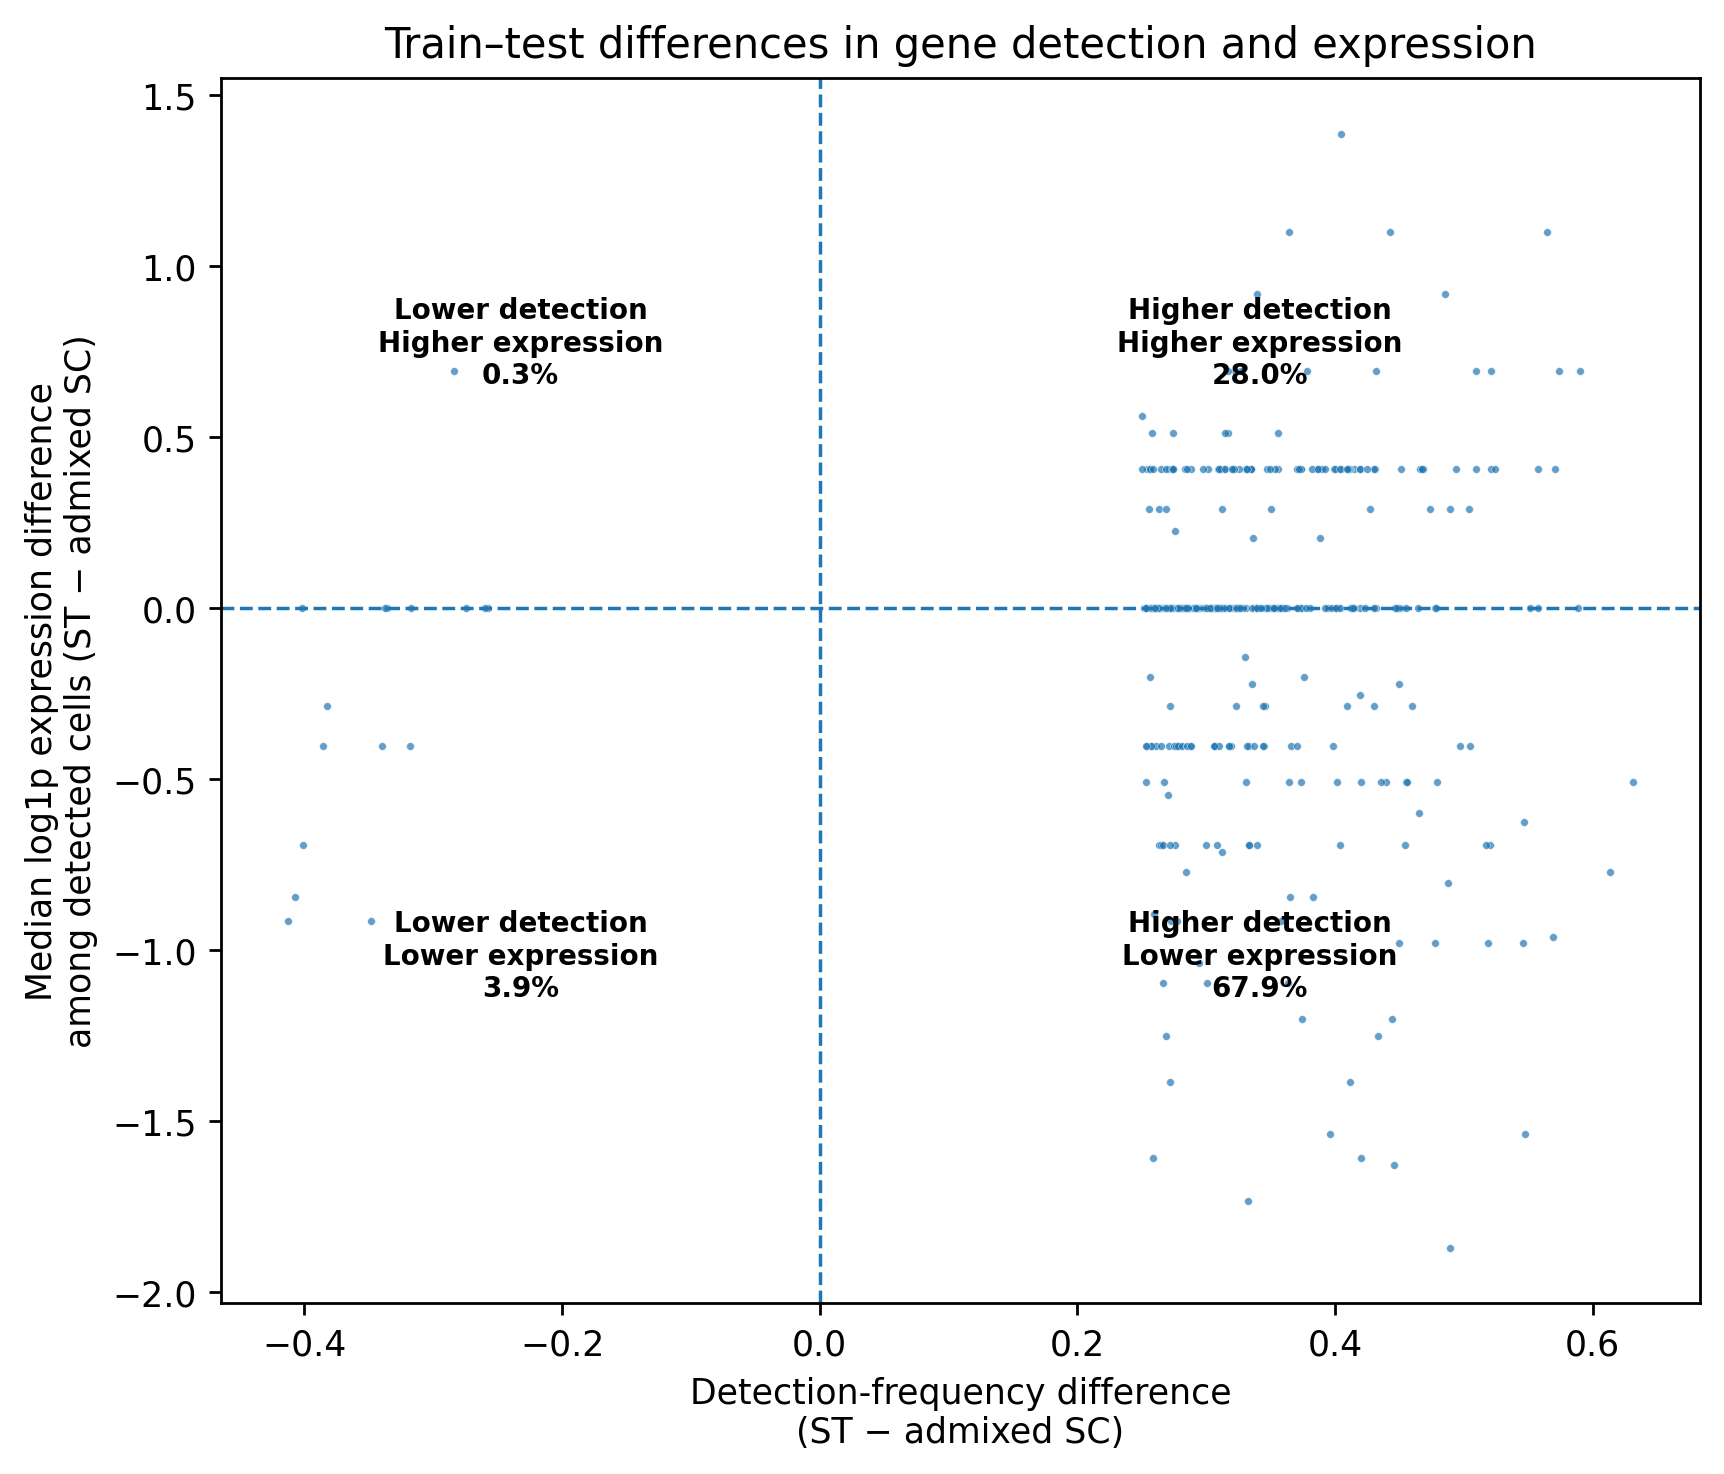

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

fig, ax = plt.subplots(figsize=(7, 6),dpi=250)

sns.scatterplot(
    data=expression_shift_df,
    x="detection_delta",
    y="median_log1p_delta",
    # hue="cell_type",
    alpha=0.7,
    ax=ax,
    s=5,
    # palette="tab20",
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "Detection-frequency difference\n(ST − admixed SC)"
)

ax.set_ylabel(
    "Median log1p expression difference\n"
    "among detected cells (ST − admixed SC)"
)

ax.set_title(
    "Train–test differences in gene detection and expression"
)


# ------------------------------------------------------------
# Calculate quadrant percentages
# ------------------------------------------------------------

x = expression_shift_df["detection_delta"]
y = expression_shift_df["median_log1p_delta"]

quadrants = {
    "upper_right": (x > 0) & (y > 0),
    "upper_left":  (x < 0) & (y > 0),
    "lower_left":  (x < 0) & (y < 0),
    "lower_right": (x > 0) & (y < 0),
}

n_total = len(expression_shift_df)

quadrant_pct = {
    name: 100 * mask.sum() / n_total
    for name, mask in quadrants.items()
}


# ------------------------------------------------------------
# Annotate quadrants
# ------------------------------------------------------------

xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()

positions = {
    "upper_left": (
        (xmin + 0) / 2,
        (0 + ymax) / 2,
    ),
    "upper_right": (
        (0 + xmax) / 2,
        (0 + ymax) / 2,
    ),
    "lower_left": (
        (xmin + 0) / 2,
        (ymin + 0) / 2,
    ),
    "lower_right": (
        (0 + xmax) / 2,
        (ymin + 0) / 2,
    ),
}

quadrant_labels = {
    "upper_right": "Higher detection\nHigher expression",
    "upper_left": "Lower detection\nHigher expression",
    "lower_left": "Lower detection\nLower expression",
    "lower_right": "Higher detection\nLower expression",
}

for quadrant, (xpos, ypos) in positions.items():
    ax.text(
        xpos,
        ypos,
        (
            f"{quadrant_labels[quadrant]}\n"
            f"{quadrant_pct[quadrant]:.1f}%"
        ),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold",
    )

fig.tight_layout()


# Optional numeric summary
pd.Series({
    **quadrant_pct,
    "n": n_total,
})

In [30]:
test_nonzero = test_adata.X.copy()
# Within ST cells where the gene is detected
frac_st_count_1 = np.mean(test_nonzero == 1)
frac_st_count_le2 = np.mean(test_nonzero <= 2)

train_nonzero = train_adata.layers['raw+admixed'].copy()
# Within training cells where detected
frac_train_count_1 = np.mean(train_nonzero == 1)
frac_train_count_le2 = np.mean(train_nonzero <= 2)

print(frac_st_count_1,frac_st_count_le2)
print(frac_train_count_1,frac_train_count_le2)

/tmp/ipykernel_3409450/1420354292.py:4: SparseEfficiencyWarning: Comparing a sparse matrix with a scalar greater than zero using <= is inefficient, try using > instead.
  frac_st_count_le2 = np.mean(test_nonzero <= 2)
/tmp/ipykernel_3409450/1420354292.py:9: SparseEfficiencyWarning: Comparing a sparse matrix with a scalar greater than zero using <= is inefficient, try using > instead.
  frac_train_count_le2 = np.mean(train_nonzero <= 2)


0.08972482618692004 0.9549169533608722
0.047057246785739526 0.9697913617363041


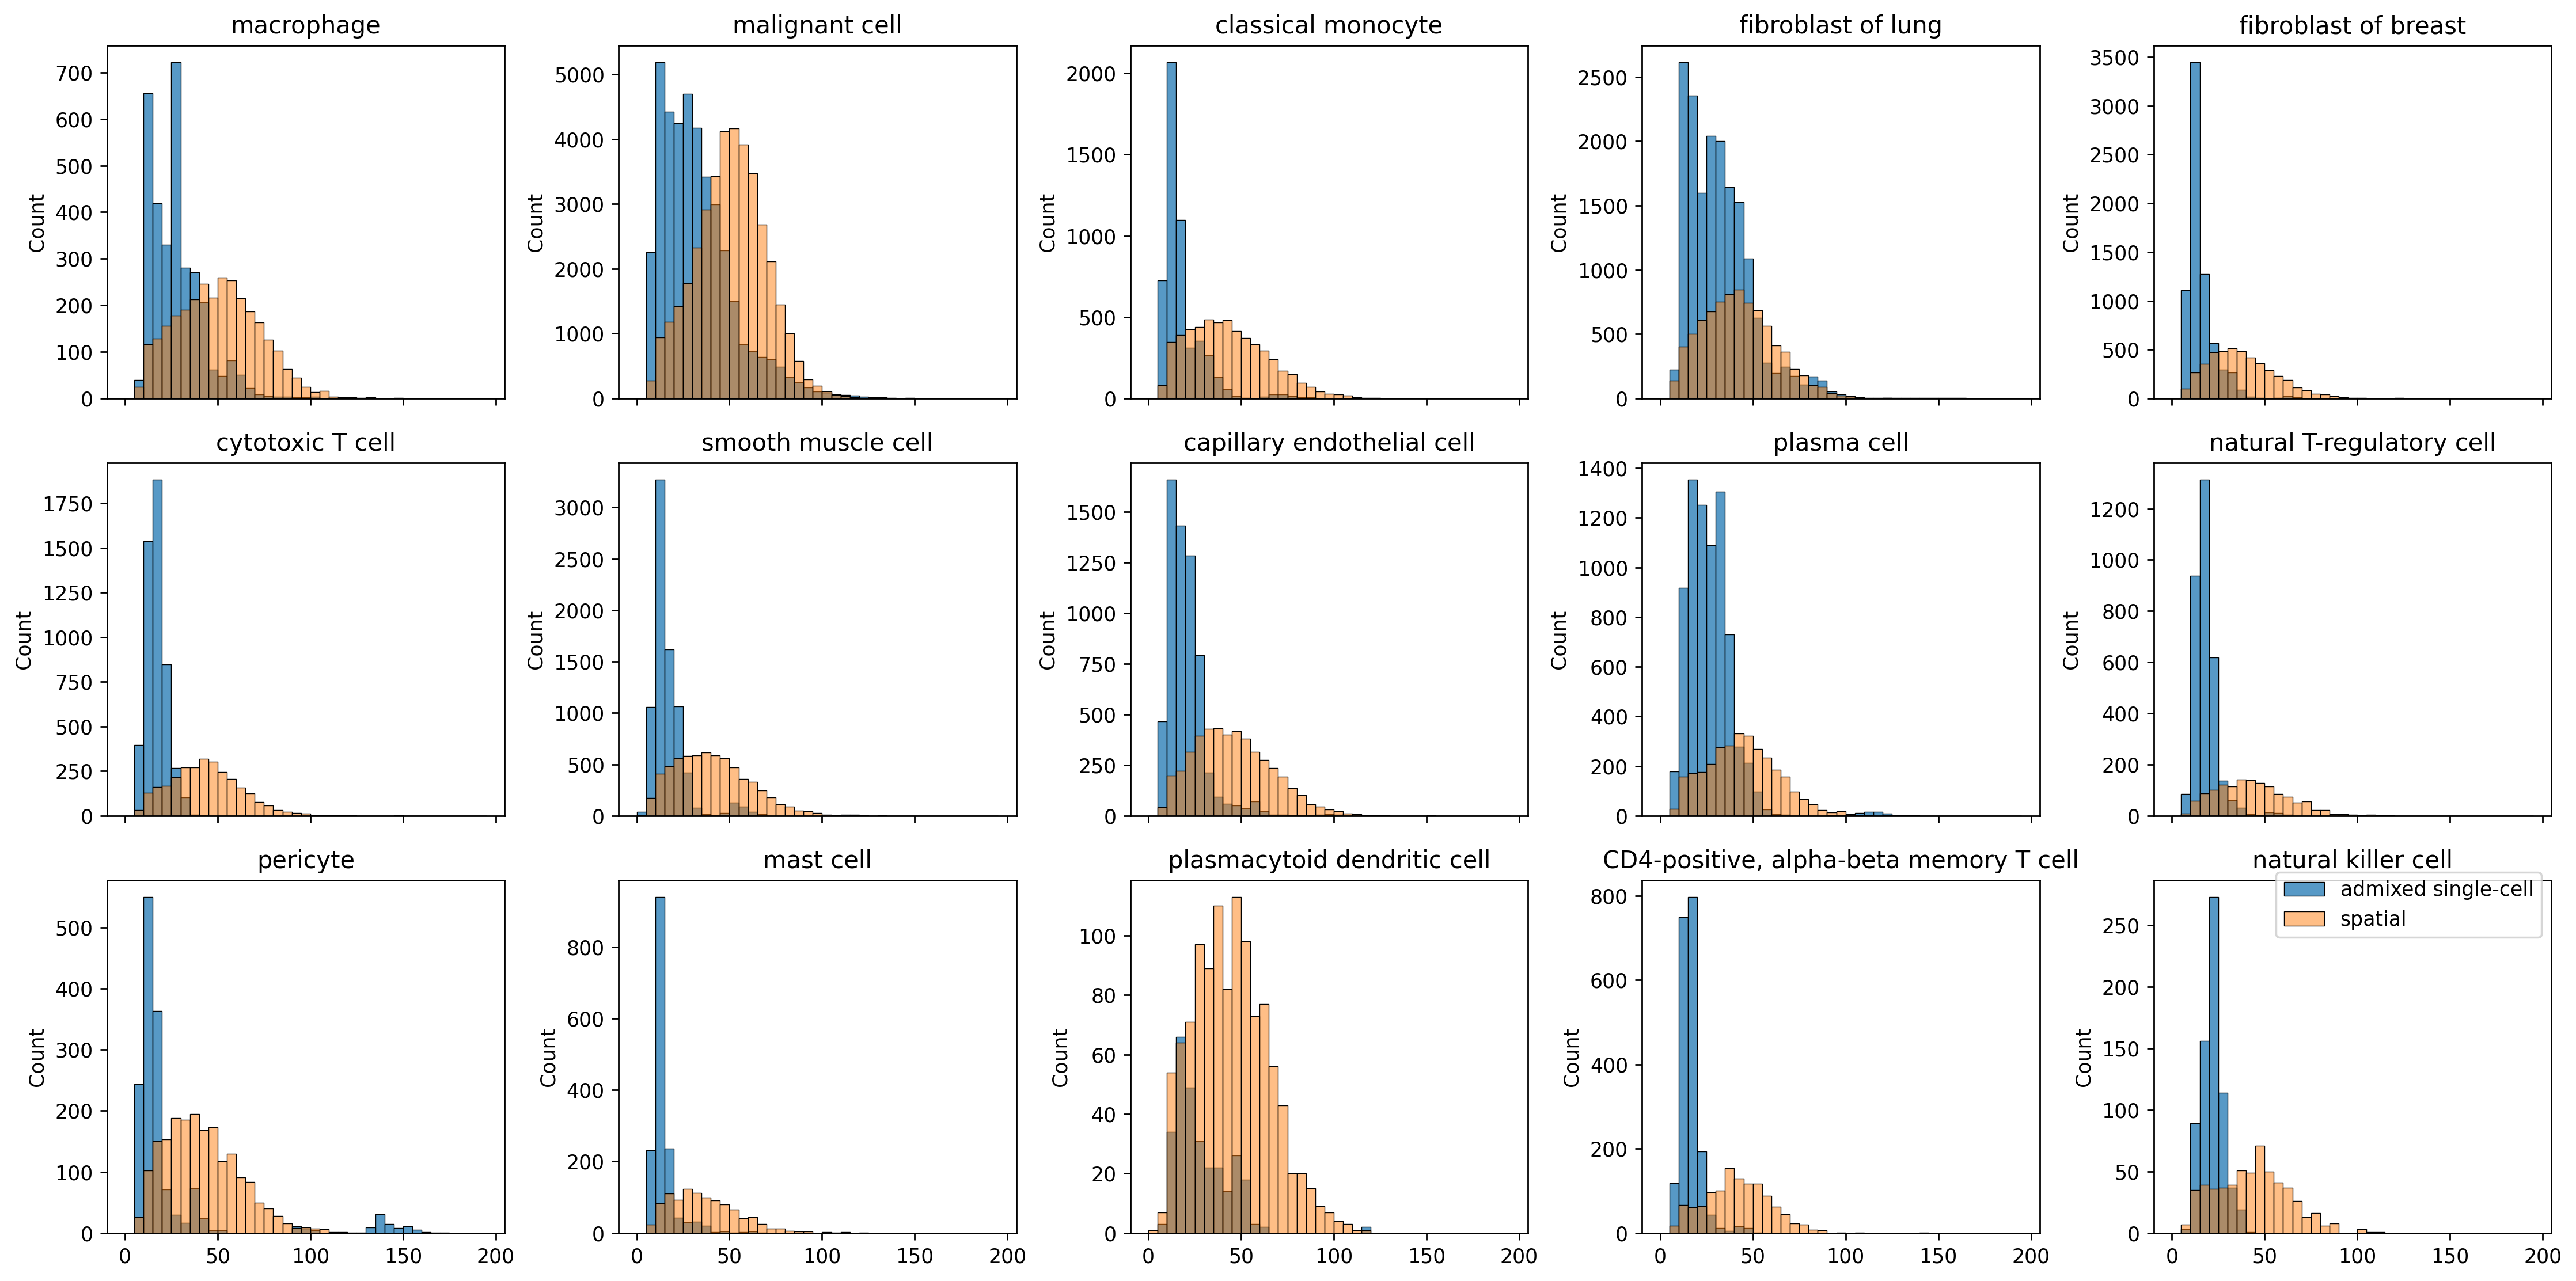

In [31]:
train_n_detected = np.asarray((train_adata.layers['raw+admixed']> 0).sum(axis=1)).ravel()
test_n_detected = np.asarray((test_adata.X > 0).sum(axis=1)).ravel()

cell_types = train_adata.obs['cell_type'].unique().tolist()
fig,axes = plt.subplots(nrows=3,ncols=5,figsize=(18,9),sharex=True,dpi=250)
for i,ax in enumerate(axes.flat):
    train_n_detected = np.asarray((train_adata[train_adata.obs['cell_type']==cell_types[i]].layers['raw+admixed']> 0).sum(axis=1)).ravel()
    test_n_detected = np.asarray((test_adata[test_adata.obs['cell_type']==cell_types[i]].X > 0).sum(axis=1)).ravel()
    sns.histplot(x=train_n_detected,ax=ax,label='admixed single-cell',bins=np.arange(0,200,5))
    sns.histplot(x=test_n_detected,alpha=0.5,ax=ax,label='spatial',bins=np.arange(0,200,5))
    ax.set_title(cell_types[i])
    if i ==14:
        ax.legend(bbox_to_anchor=(1,1.05))

fig.tight_layout()

<Axes: ylabel='Count'>

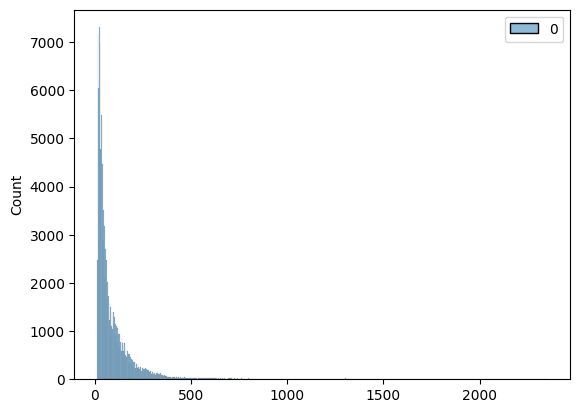

In [71]:
train_adata.layers['raw+admixed'].sum(axis=1),test_adata.X.sum(axis=1)

sns.histplot(train_adata.layers['raw+admixed'].sum(axis=1),label='train')
# sns.histplot(test_adata.X.sum(axis=1),label='test')

In [61]:
expression_shift_df["pattern"] = np.select(
    [
        (expression_shift_df["detection_delta"] > 0)
        & (expression_shift_df["median_log1p_delta"] > 0),

        (expression_shift_df["detection_delta"] > 0)
        & (expression_shift_df["median_log1p_delta"] == 0),

        (expression_shift_df["detection_delta"] > 0)
        & (expression_shift_df["median_log1p_delta"] < 0),

        (expression_shift_df["detection_delta"] < 0)
        & (expression_shift_df["median_log1p_delta"] > 0),

        (expression_shift_df["detection_delta"] < 0)
        & (expression_shift_df["median_log1p_delta"] < 0),
    ],
    [
        "More detected + higher in ST",
        "More detected + same in ST",
        "More detected + lower in ST",
        "Less detected + higher in ST",
        "Less detected + lower in ST",
    ],
    default="Other",
)

expression_shift_df["pattern"].value_counts()

pattern
More detected + lower in ST     248
More detected + higher in ST    109
Less detected + lower in ST      14
Less detected + higher in ST      1
Name: count, dtype: int64